# Model 4: Gradient Boosted Trees 

**Algorithm**: Gradient Boosted Trees  
**Type**: Boosting Ensemble  
**Goal**: Build trees sequentially, each correcting previous errors

## 1. Setup

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, countDistinct, sum as spark_sum, lit
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml import Pipeline
from pyspark.mllib.evaluation import MulticlassMetrics
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("Model4_GradientBoosting").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("WARN")
print("✓ Spark started")

26/10/17 15:04:39 WARN Utils: Your hostname, Kireetis-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.12.112.156 instead (on interface en0)
26/10/17 15:04:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/17 15:04:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


✓ Spark started


## 2. Load and Prepare Data

This exploratory classifier identifies whether an aggregated visitor history contains a transaction. It uses behavioural features only; transaction count creates the label and is not a predictor.

For a production future-purchase model, create features before a defined cutoff and label purchases after it.

In [2]:
df = spark.read.option("header", True).option("inferSchema", True).csv("../data/events.csv")

# Define inputs once; reuse them in the assembler and feature-importance chart.
feature_columns = [
    "view_count", "cart_count", "unique_items_viewed",
    "unique_items_carted", "active_days", "cart_to_view_ratio"
]

visitor_features = df.groupBy("visitorid").agg(
    spark_sum(when(col("event") == "view", 1).otherwise(0)).alias("view_count"),
    spark_sum(when(col("event") == "addtocart", 1).otherwise(0)).alias("cart_count"),
    countDistinct(when(col("event") == "view", col("itemid"))).alias("unique_items_viewed"),
    countDistinct(when(col("event") == "addtocart", col("itemid"))).alias("unique_items_carted"),
    countDistinct((col("timestamp") / lit(86400000)).cast("long")).alias("active_days"),
    spark_sum(when(col("event") == "transaction", 1).otherwise(0)).alias("transaction_count")
)

visitor_features = (visitor_features
    .withColumn("cart_to_view_ratio", when(col("view_count") > 0, col("cart_count") / col("view_count")).otherwise(0.0))
    .withColumn("label", when(col("transaction_count") > 0, 1.0).otherwise(0.0))
)

model_data = visitor_features.select(*feature_columns, "label")
print(f"✓ Data prepared: {model_data.count():,} visitors")

✓ Data prepared: 1,407,580 visitors


## 3. Train-Test Split

This reproducible random split holds out visitors, not future time periods.

In [3]:
train_data, test_data = model_data.randomSplit([0.8, 0.2], seed=42)
print(f"Training: {train_data.count():,}")
print(f"Testing:  {test_data.count():,}")

26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:46 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:47 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:49 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:55 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


Testing:  280,885


## 4. Build Gradient Boosted Trees

**How Boosting Works:**
1. Train Tree 1 → makes some mistakes
2. Train Tree 2 → focuses on Tree 1's mistakes
3. Train Tree 3 → focuses on remaining mistakes
4. ... continue ...
5. Final prediction = weighted combination of all trees

**Result**: Each tree corrects previous errors!

In [4]:
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

gbt = GBTClassifier(
    featuresCol="features",
    labelCol="label",
    maxIter=30,        # Number of boosting rounds
    maxDepth=5,        # Max depth per tree
    seed=42
)

pipeline = Pipeline(stages=[assembler, gbt])
print("✓ Pipeline created with 30 iterations")

✓ Pipeline created with 30 iterations


## 5. Train Model

This takes longer because trees are built sequentially

In [5]:
print("Training Gradient Boosted Trees...")
print("(This may take a few minutes)")
model = pipeline.fit(train_data)
print("✓ Training complete!")

Training Gradient Boosted Trees...
(This may take a few minutes)


26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:04:58 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:04:59 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:00 WARN RowBasedKeyValueBatch: Calling spill() on

...

26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:04 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:05 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


✓ Training complete!


## 6. Make Predictions

In [6]:
predictions = model.transform(test_data)
predictions.select("view_count", "cart_count", "label", "prediction").show(10)

26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:36 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:05:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:50 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


+----------+----------+-----+----------+
|view_count|cart_count|label|prediction|
+----------+----------+-----+----------+
|         0|         0|  1.0|       1.0|
|         0|         0|  1.0|       1.0|
|         0|         0|  1.0|       1.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
+----------+----------+-----+----------+
only showing top 10 rows



26/10/17 15:05:52 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/10/17 15:05:52 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


## 7. Evaluate Performance

In [7]:
prediction_labels = predictions.select(
    col("prediction").cast("double"),
    col("label").cast("double")
)

metrics = MulticlassMetrics(prediction_labels.rdd.map(lambda row: (row[0], row[1])))

accuracy = metrics.accuracy
precision = metrics.precision(1.0)
recall = metrics.recall(1.0)
f1 = metrics.fMeasure(1.0)

print("=" * 50)
print("GRADIENT BOOSTED TREES PERFORMANCE")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("=" * 50)
print("=" * 50)

26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:53 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:55 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:05:56 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:06:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


/Users/kireeti/Desktop/Projects/SparkProejct/.venv/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


GRADIENT BOOSTED TREES PERFORMANCE
Accuracy:  0.9919 (99.19%)
Precision: 0.6111
Recall:    0.0894
F1-Score:  0.1560


## 8. Visualizations

In [8]:
cm = metrics.confusionMatrix().toArray()
gbt_model = model.stages[1]

###  Confusion Matrix

**Explanation**: The confusion matrix displays the current run's true positives, false positives, true negatives, and false negatives.

/var/folders/8t/p_kcbwsj6bd20k8tyrsx54rw0000gn/T/ipykernel_5269/2624139443.py:14: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/Users/kireeti/Desktop/Projects/SparkProejct/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


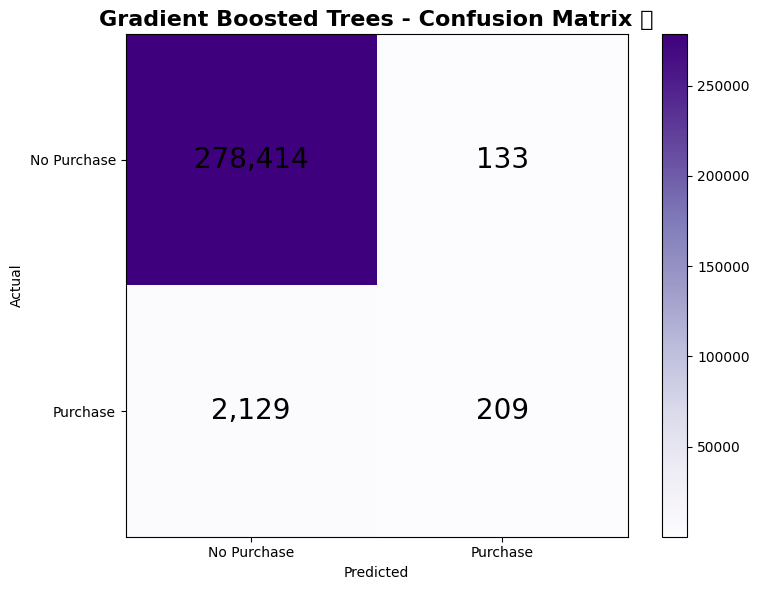

In [9]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Purples')
plt.title('Gradient Boosted Trees - Confusion Matrix 🏆', fontsize=16, fontweight='bold')
plt.colorbar()
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.yticks([0, 1], ['No Purchase', 'Purchase'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{int(cm[i, j]):,}', ha="center", va="center", fontsize=20)

plt.tight_layout()
plt.show()

### Feature Importance

**Explanation**: Importance shows how much the fitted model used each behavioural feature. Interpret it as association, not causation.

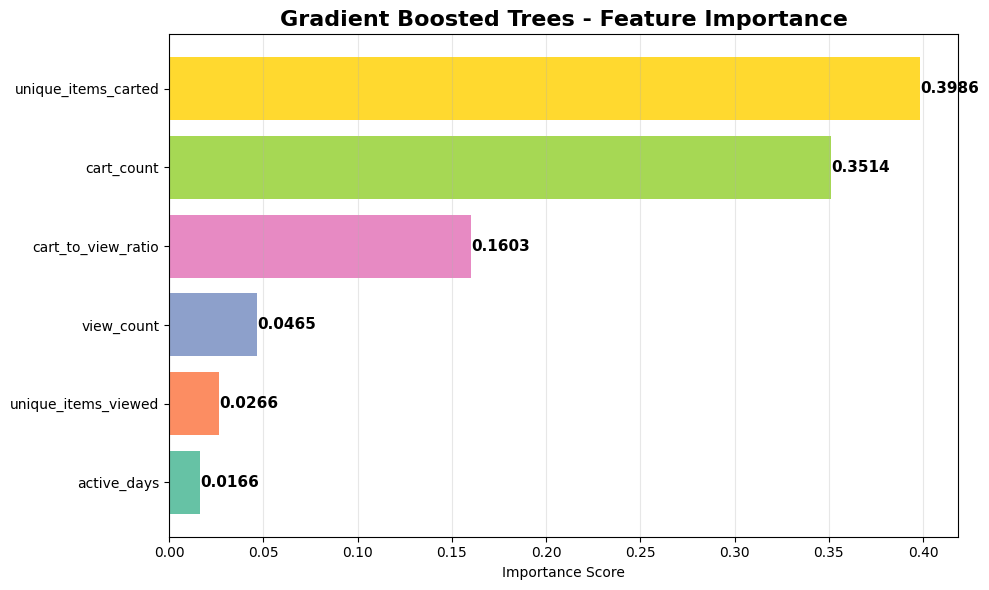


Feature Importance (highest first):
unique_items_carted: 0.3986
cart_count: 0.3514
cart_to_view_ratio: 0.1603
view_count: 0.0465
unique_items_viewed: 0.0266
active_days: 0.0166


In [10]:
# Pair each feature with the score learned by the fitted model.
feature_importance = sorted(
    zip(feature_columns, gbt_model.featureImportances.toArray()),
    key=lambda pair: pair[1]
)
features, importances = zip(*feature_importance)

plt.figure(figsize=(10, 6))
colors = plt.cm.Set2(range(len(features)))
bars = plt.barh(features, importances, color=colors)
plt.title('Gradient Boosted Trees - Feature Importance', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score')
plt.grid(axis='x', alpha=0.3)

# Add value labels
for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2.,
             f'{width:.4f}',
             ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nFeature Importance (highest first):")
for feat, imp in reversed(list(zip(features, importances))):
    print(f"{feat}: {imp:.4f}")

### Current Model Metrics

**Explanation**: This chart reports accuracy and F1-score from the current Gradient Boosting run.

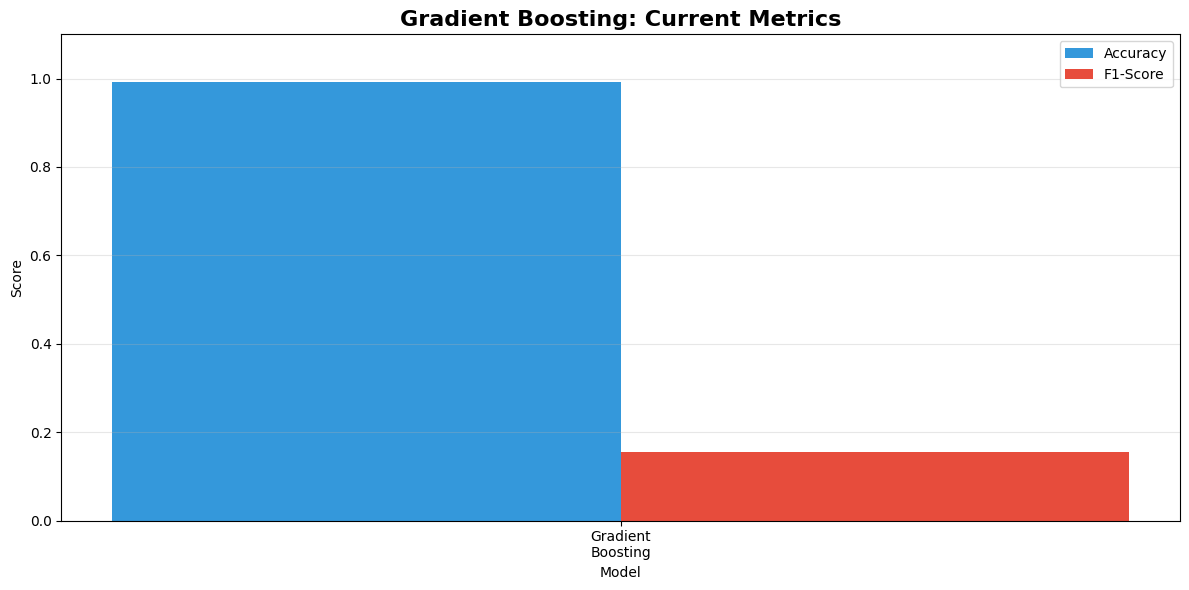

In [11]:
# Current-model metrics. Add other models only after re-running them with this feature set.
models = ['Gradient\nBoosting']
accuracies = [accuracy]
f1_scores = [f1]

x = range(len(models))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar([i - width/2 for i in x], accuracies, width, label='Accuracy', color='#3498db')
plt.bar([i + width/2 for i in x], f1_scores, width, label='F1-Score', color='#e74c3c')

plt.title('Gradient Boosting: Current Metrics', fontsize=16, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(x, models)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Stop Spark

In [12]:
spark.stop()
print("✓ Done!")

✓ Done!


---
## Summary

**Current Gradient Boosted Trees run:**
- Review the accuracy, precision, recall, and F1-score printed above.
- The values update whenever the notebook is re-run.

**Why use Gradient Boosting?**
1. Learns from previous trees' mistakes
2. Reduces both bias and variance
3. Handles complex non-linear patterns
4. Can model interactions among behavioural features

**Trade-offs:**
- Slower training (sequential building)
- More complex to tune
- Less interpretable than single tree

**Recommendation**: Do not select a production model until it has been evaluated with a time-based validation design.